In [1]:
#julia -t 4

using Plots
using Random, Statistics, Distributions
using SparseArrays
using LinearAlgebra
using DifferentialEquations
using StatsPlots 

using Statistics 
using Distributions, Random, Plots, StatsBase  
using Base.Threads



include("../GPs.jl")
include("../functions.jl")
include("../myfuncs.jl")
include("../integrators.jl")
include("../util_shoji.jl")


simulate_pf_selforg (generic function with 1 method)

Maximum error = 0.0008084398633819954
L2 error       = 0.000601071860383032


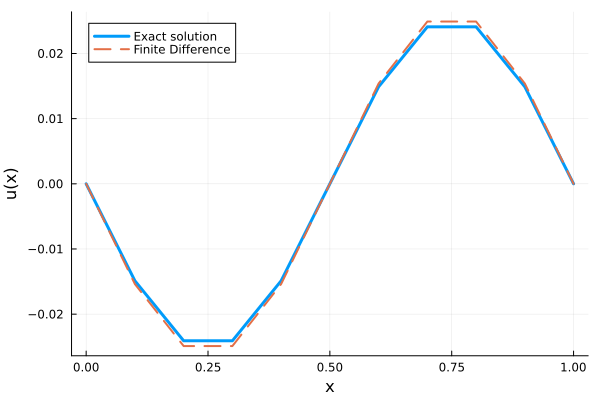

In [2]:
using LinearAlgebra
using Plots

# -----------------------------
# Problem setting
# -----------------------------

dt = 0.1
T = 1.0
x = 0:dt:T


xi = x[2:end-1]
n = length(xi)

# -----------------------------
# Construct finite difference matrix
# -u'' = f
# -----------------------------
A = zeros(n, n)

for i in 1:n
    A[i,i] = 2.0
    if i > 1
        A[i,i-1] = -1.0
    end
    if i < n
        A[i,i+1] = -1.0
    end
end

A ./= (dt)^2

# Right-hand side
f = -sin.(2π .* xi)

# Solve linear system
u_interior = A \ f

# Include boundary values
u_num = vcat(0.0, u_interior, 0.0)

# -----------------------------
# Exact solution
# -----------------------------
u_exact_vec = -(1/(2π)^2) .* sin.(2π .* x)

# -----------------------------
# Error
# -----------------------------
max_error = maximum(abs.(u_num .- u_exact_vec))
l2_error = sqrt(sum((u_num .- u_exact_vec).^2) * (dt))

println("Maximum error = ", max_error)
println("L2 error       = ", l2_error)

# -----------------------------
# Plot
# -----------------------------
plot(x, u_exact_vec,
    lw=3,
    label="Exact solution",
    xlabel="x",
    ylabel="u(x)")

plot!(x, u_num,
    linestyle=:dash,
    lw=2,
    label="Finite Difference")

In [5]:
ℓ =20.0
σf =20.0
prior_mean = 0.0
#obs_noise = dt^4

x_all = collect(0:dt:1)
n = length(x_all)
X_test =
    collect(
        range(
            0.0,
            1.0,
            length=500
        )
    )

println("x_all:", x_all)
println("x_all.size:", x_all.size)
println("n:", n)
println("X_test:", X_test.size)
Ktest = kernel_matrix(X_test, x_all)

function laplacian_matrix(n, dt)

    # n = number of grid points (including boundary)
    D = zeros(n-2, n)

    for i in 1:n-2
        D[i,i]   = 1
        D[i,i+1] = -2
        D[i,i+2] = 1
    end

    return D ./ dt^2
end

function laplacian_matrix(n, dt)

    # n = number of grid points (including boundary)
    D = zeros(n-2, n)

    for i in 1:n-2
        #D[i,i]   = 1
        D[i,i] = 1
        #D[i,i+2] = 1
    end

    return D 
end




function observation_matrix(n, dt)

    D = laplacian_matrix(n, dt)

    H = zeros(n, n)

    # u(0)
    H[1,1] = 1.0

    # Lu (internal)
    H[2:n-1, :] .= D

    # u(1)
    H[end,end] = 1.0

    return H
end

H = observation_matrix(length(x_all), dt)

println("H:", H)
println("H.size:", H.size)


Kuu = kernel_matrix(
    x_all,
    x_all;
    ℓ=ℓ,
    σf=σf
)


Kobs = H * Kuu * H'
Kobs += 1e-8I

println("Ks.size;", Ks.size)
println("H.size;", H.size)

Ks = Ktest * H'

println("Kobs:", Kobs.size)
println("Ks:", Ks.size)

x_all:[0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
x_all.size:(11,)
n:11
X_test:(500,)
H:[1.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0; 1.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0; 0.0 1.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0; 0.0 0.0 1.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0; 0.0 0.0 0.0 1.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0; 0.0 0.0 0.0 0.0 1.0 0.0 0.0 0.0 0.0 0.0 0.0; 0.0 0.0 0.0 0.0 0.0 1.0 0.0 0.0 0.0 0.0 0.0; 0.0 0.0 0.0 0.0 0.0 0.0 1.0 0.0 0.0 0.0 0.0; 0.0 0.0 0.0 0.0 0.0 0.0 0.0 1.0 0.0 0.0 0.0; 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 1.0 0.0 0.0; 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 1.0]
H.size:(11, 11)
Ks.size;(500, 11)
H.size;(11, 11)
Kobs:(11, 11)
Ks:(500, 11)


y:[0.0, -0.5877852522924731, -0.9510565162951535, -0.9510565162951536, -0.5877852522924732, -1.2246467991473532e-16, 0.587785252292473, 0.9510565162951535, 0.9510565162951536, 0.5877852522924734, 0.0]
μ:[-1.1891802608497506e6, -1.1856150666041267e6, -1.1820282582703312e6, -1.178419887308571e6, -1.1747900057282976e6, -1.1711386660872705e6, -1.1674659214905815e6, -1.1637718255896682e6, -1.160056432581326e6, -1.1563197972066575e6, -1.1525619747500399e6, -1.1487830210380948e6, -1.1449829924385685e6, -1.1411619458592397e6, -1.1373199387468866e6, -1.1334570290860129e6, -1.1295732753978143e6, -1.1256687367390278e6, -1.1217434727006077e6, -1.117797543406702e6, -1.1138310095133109e6, -1.1098439322070838e6, -1.1058363732041367e6, -1.101808394748612e6, -1.0977600596115568e6, -1.0936914310895817e6, -1.089602573003466e6, -1.0854935496968552e6, -1.0813644260349497e6, -1.0772152674030697e6, -1.073046139705292e6, -1.0688571093630076e6, -1.0646482433135568e6, -1.0604196090086992e6, -1.0561712744132576e

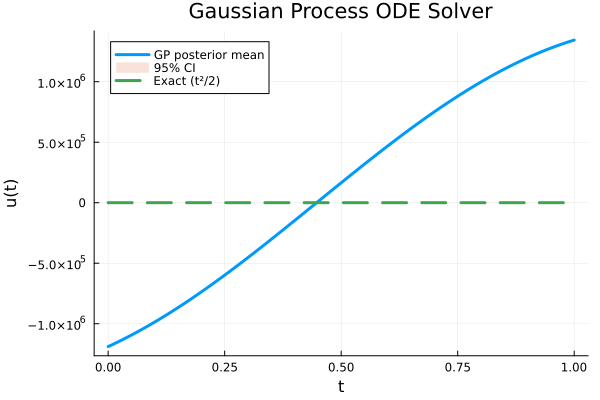

"/Users/shoji/Project_with_Jon/Poisson Equation/a.png"

In [8]:
m_y = vcat([prior_mean],  zeros(length(x_all)), [prior_mean])
m_x = fill(prior_mean, length(X_test))

x_obs = collect(dt:dt:1-dt)
rhs = -sin.(2π .* x_obs)

y = vcat(
    [0.0],        # u(0)
    rhs,          # Δu
    [0.0]         # u(1)
)

println("y:", y)

Kss = kernel_matrix(
    X_test,
    X_test;
    ℓ=ℓ,
    σf=σf
)

μ =  Ks * (Kobs \ (y ))

Σ = Kss - Ks * (Kobs \ Ks')

println("μ:", μ)


std =
    sqrt.(max.(diag(Σ),0))

# =====================================================
# Exact solution
# =====================================================



u_exact(t) = -(1/(2π)^2) * sin(2π * t)


# =====================================================
# Plot
# =====================================================

plot(
    X_test,
    μ,
    lw=3,
    label="GP posterior mean"
)

plot!(
    X_test,
    μ .+ 1.96 .* std,
    fillrange=
        μ .- 1.96 .* std,
    fillalpha=0.2,
    linealpha=0,
    label="95% CI"
)

plot!(
    X_test,
    u_exact.(X_test),
    lw=3,
    ls=:dash,
    label="Exact (t²/2)"
)

μ_prior = zeros(length(X_test))



std_prior = sqrt.(diag(Kss))


μ_prior = fill(prior_mean, length(X_test))

println(std_prior)

#plot!(
#    X_test,
#    ylims = (-10.0, 10.0),
#    μ_prior .+ 1.96 .* std_prior,
#    fillrange = μ_prior .- 1.96 .* std_prior,
#    fillalpha = 0.1,
#    linealpha = 0,
#    label = "prior 95% CI"
#)

xlabel!("t")
ylabel!("u(t)")
title!("Gaussian Process ODE Solver")

display(current())

savefig("a.png")